# 📊 Trabajo Práctico \- Análisis Exploratorio de Datos \(EDA\)

## Materia: Desarrollo de Sistemas de Inteligencia Artificial

## Grupo N° 1

### Integrantes del grupo:

Jorge A. Mendoza \- Dataset: Bank Marketing (bank-additional)
Constanza Soler \- Dataset: Superficie de viñedos 2025 (inv-superficie-viniedos-2025)
Catalina Frione \- Dataset: Adolescentes y videojuegos, Andalucía 2023 (adolescentes_andalucia_2023)
Franco Alfredo Díaz \- Dataset: Estimaciones agrícolas (estimaciones-agricolas-2026-03)
Federico Suárez \- Dataset: Exoplanetas 2021 (all_exoplanets_2021)

# PRIMERA ENTREGA

## 👉🏻 Consigna

Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato \.csv o \.xlsx, al menos 9 columnas y 2500 filas\. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una conclusión grupal que justifica la elección del dataset con el que se continuará el desarrollo del proyecto\.

## 🔍 Introducción

En esta primera entrega cada integrante presenta un análisis exploratorio (EDA) de su propio dataset: banca, vitivinicultura, videojuegos en adolescentes, agricultura y exoplanetas. En cada caso revisamos la estructura de los datos, su calidad y dos visualizaciones clave. Al final comparamos los datasets y elegimos uno para seguir con el proyecto.

# 📁 Dataset 1 – Bank Marketing \(Integrante: Jorge A. Mendoza\)

## 📝 Descripción del Dataset

El dataset contiene información de campañas de marketing telefónico de un banco portugués. Cada fila es un cliente contactado, con datos personales (edad, trabajo, estado civil), datos del contacto (mes, duración, cantidad de llamadas) e indicadores económicos. La variable objetivo "y" indica si el cliente contrató o no un depósito a plazo.

## Importación de Librerías

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1\. Carga y exploración de datos

### Carga del dataset y estructura general

Se carga el archivo (separado por ";") y se revisan dimensiones, tipos de datos y primeras filas.

In [3]:
df_bank = pd.read_csv("bank-additional.csv", sep=";")
print("Dimensiones:", df_bank.shape)
df_bank.info()
df_bank.head()

Dimensiones: (4119, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   object 
 2   marital         4119 non-null   object 
 3   education       4119 non-null   object 
 4   default         4119 non-null   object 
 5   housing         4119 non-null   object 
 6   loan            4119 non-null   object 
 7   contact         4119 non-null   object 
 8   month           4119 non-null   object 
 9   day_of_week     4119 non-null   object 
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   object 
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


El dataset tiene **4119 filas y 21 columnas**: 10 numéricas y 11 categóricas. Cumple con los requisitos mínimos.

### Valores faltantes y valores "unknown"

Se verifica la presencia de nulos. Como las categóricas usan la etiqueta "unknown" en lugar de nulo, también se cuentan esos casos.

In [5]:
print("Nulos totales:", df_bank.isnull().sum().sum())
print("Filas duplicadas:", df_bank.duplicated().sum())
print("\nCantidad de 'unknown' por columna:")
print((df_bank == "unknown").sum()[lambda s: s > 0])

Nulos totales: 0
Filas duplicadas: 0

Cantidad de 'unknown' por columna:
job           39
marital       11
education    167
default      803
housing      105
loan         105
dtype: int64


No hay nulos ni duplicados, pero sí hay valores "unknown". La columna "default" es la más afectada (803 casos, ~20%).

## 2\. Visualizaciones y análisis

### Distribución de la variable objetivo \(y\)

Se grafica cuántos clientes aceptaron el depósito y cuántos no.

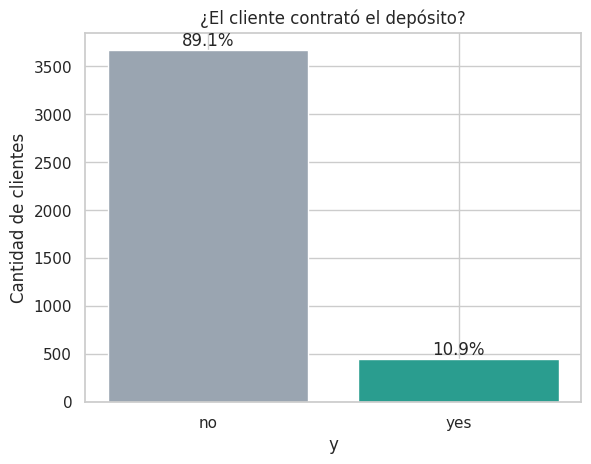

In [53]:
conteo = df_bank["y"].value_counts()

plt.bar(conteo.index, conteo.values, color=["#9aa5b1", "#2a9d8f"])
for i, v in enumerate(conteo.values):
    plt.text(i, v, f"{v / len(df_bank):.1%}", ha="center", va="bottom")
plt.title("¿El cliente contrató el depósito?")
plt.xlabel("y")
plt.ylabel("Cantidad de clientes")
plt.show()

📌 Solo el **11%** de los clientes contrató el depósito. La clase objetivo está muy desbalanceada, y eso habrá que tenerlo en cuenta si se entrena un modelo de clasificación.

### Duración de la llamada según resultado

Se compara la duración de la última llamada (en segundos) entre quienes aceptaron y quienes no.

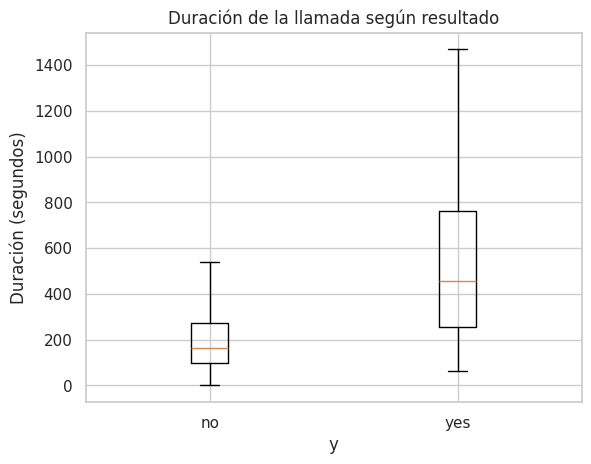

In [55]:
grupos = [df_bank[df_bank["y"] == "no"]["duration"], df_bank[df_bank["y"] == "yes"]["duration"]]

plt.boxplot(grupos, showfliers=False)
plt.xticks([1, 2], ["no", "yes"])
plt.title("Duración de la llamada según resultado")
plt.xlabel("y")
plt.ylabel("Duración (segundos)")
plt.show()

📌 Las llamadas que terminan en "sí" son bastante más largas (mediana de ~458 s contra ~165 s). Sin embargo, la duración se conoce recién al terminar la llamada, así que no serviría para predecir antes del contacto.

## 3\. Observaciones generales

- Datos limpios en cuanto a nulos, aunque con varios "unknown" en variables categóricas.
- Variable objetivo muy desbalanceada (89% / 11%).
- Las variables más interesantes son "duration", "poutcome" (resultado de campañas anteriores) y los indicadores económicos.

# 📁 Dataset 2 – Superficie de viñedos 2025 \(Integrante: Constanza Soler\)

## 📝 Descripción del Dataset

Registro del Instituto Nacional de Vitivinicultura (INV) con la superficie cultivada con vid en Argentina en 2025. Cada fila indica una parcela por provincia, departamento y localidad, con la variedad de uva, su color, el año de plantación, el sistema de conducción y la superficie plantada en hectáreas.

## Importación de Librerías

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

## 1\. Carga y exploración de datos

### Lectura del archivo

Leemos el CSV y miramos cuántas filas y columnas tiene, junto con una muestra de los datos.

In [11]:
vinedos = pd.read_csv("inv-superficie-viniedos-2025.csv")
print(vinedos.shape)
vinedos.sample(5, random_state=1)

(85740, 16)


,anio,provincia,provincia_id,departamento,departamento_id,localidad,localidad_id,variedad,color,anio_plantacion,estado_variedad,tipo_uva,sistema_conduccion,tipo_pie,pie,superficie_plantada
38274,2025,Mendoza,50,San Martín,50098,Alto Verde,50098020,Criolla Grande,rosada,1960,productiva,común,parral,franco,si,1.7000
19628,2025,Mendoza,50,Lavalle,50056,Ingeniero Gustavo André,50056110,Torrontes Riojano,blanca,2012,productiva,fina,espaldera alta,franco,si,2.0000
78105,2025,San Juan,70,San Martín,70091,Dos Acequias,70091020,Cereza,rosada,1993,productiva,común,parral,franco,si,1.8948
18452,2025,Mendoza,50,Lavalle,50056,Costa de Araujo,50056080,Pedro Gimenez,blanca,1961,productiva,fina,parral,franco,si,1.1550
10115,2025,Mendoza,50,Junín,50035,Junín,50035020,Moscatel Rosado,rosada,1982,productiva,común,parral,franco,si,0.7910


Tenemos **85.740 registros y 16 columnas**. La mayoría son categóricas (ubicación, variedad, tipo de uva) y la variable numérica principal es "superficie_plantada".

### Tipos de datos, nulos y resumen numérico

Revisamos los tipos de dato, si hay nulos y las estadísticas básicas de las columnas numéricas.

In [15]:
vinedos.info()
print("\nNulos por columna:", vinedos.isna().sum().sum())
vinedos[["anio_plantacion", "superficie_plantada"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85740 entries, 0 to 85739
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   anio                 85740 non-null  int64  
 1   provincia            85740 non-null  object 
 2   provincia_id         85740 non-null  int64  
 3   departamento         85740 non-null  object 
 4   departamento_id      85740 non-null  int64  
 5   localidad            85740 non-null  object 
 6   localidad_id         85740 non-null  object 
 7   variedad             85740 non-null  object 
 8   color                85740 non-null  object 
 9   anio_plantacion      85740 non-null  int64  
 10  estado_variedad      85740 non-null  object 
 11  tipo_uva             85740 non-null  object 
 12  sistema_conduccion   85740 non-null  object 
 13  tipo_pie             85740 non-null  object 
 14  pie                  85740 non-null  object 
 15  superficie_plantada  85740 non-null 

,anio_plantacion,superficie_plantada
count,85740.000000,85740.000000
mean,1990.671367,2.288548
std,23.058816,3.730277
min,1780.000000,0.000000
25%,1972.000000,0.500000
50%,1999.000000,1.250000
75%,2009.000000,2.636125
max,2025.000000,123.200000


- No hay valores nulos.
- "anio" vale 2025 en todas las filas, así que no aporta información.
- Hay plantaciones registradas desde 1780, y la superficie por registro va de 0 a 123 ha.

## 2\. Visualizaciones y análisis

### Superficie plantada por provincia

Sumamos las hectáreas por provincia para ver dónde se concentra el viñedo argentino.

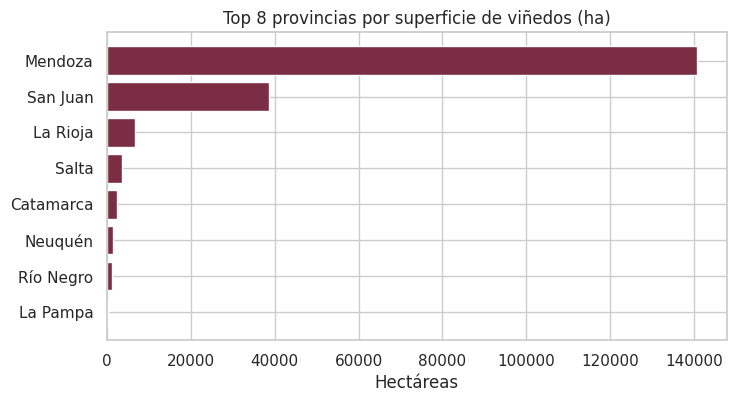

In [17]:
por_prov = vinedos.groupby("provincia")["superficie_plantada"].sum().sort_values().tail(8)

plt.figure(figsize=(8, 4))
plt.barh(por_prov.index, por_prov.values, color="#7b2d43")
plt.title("Top 8 provincias por superficie de viñedos (ha)")
plt.xlabel("Hectáreas")
plt.show()

📌
- **Mendoza** tiene el ~72% de la superficie y **San Juan** otro ~20%.
- Entre las dos suman más del 90% del total. El resto de las provincias tiene muy poca superficie.

### Variedades con más superficie

Vemos cuáles son las 10 variedades de uva con más hectáreas plantadas.

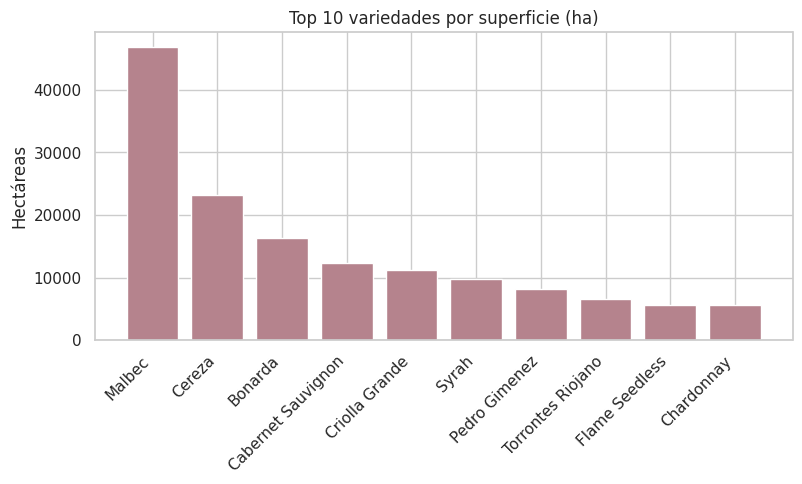

In [19]:
por_var = vinedos.groupby("variedad")["superficie_plantada"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 4))
plt.bar(por_var.index, por_var.values, color="#b5838d")
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 variedades por superficie (ha)")
plt.ylabel("Hectáreas")
plt.show()

📌
- **Malbec** es claramente la principal, con casi el 24% del total.
- Le siguen Cereza y Bonarda, dos uvas asociadas a vinos de mesa o de mayor volumen.

## 3\. Observaciones generales

- Buena calidad de datos: sin nulos y con columnas bien definidas.
- Hay mucha concentración geográfica (Mendoza y San Juan) y varietal (Malbec).
- Las variables más interesantes son "variedad", "color", "anio_plantacion" y "sistema_conduccion". La principal limitación es que el dataset es de un solo año.

# 📁 Dataset 3 – Adolescentes y videojuegos, Andalucía 2023 \(Integrante: Catalina Frione\)

## 📝 Descripción del Dataset

Encuesta a estudiantes de secundaria de Andalucía (España) sobre el uso de videojuegos. Incluye edad, sexo, curso, horas semanales de juego, plataforma y género preferido, puntajes de la escala **GD-20** de trastorno por videojuegos (con sus subescalas) y puntajes de habilidades socioemocionales (SEL).

## Importación de Librerías

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_palette("pastel")

## 1\. Carga y exploración de datos

### Carga y primer vistazo

Cargo el dataset y miro sus dimensiones y las primeras filas.

In [23]:
datos = pd.read_csv("adolescentes_andalucia_2023.csv", encoding="utf-8-sig")
print(f"Filas: {datos.shape[0]} | Columnas: {datos.shape[1]}")
datos.head()

Filas: 3579 | Columnas: 21


,Edad,Sexo,Curso,IES,Provincia,Horas_semana,Plataforma_juego,Género_juego,GD_Prominencia,GD_Animo,...,GD_Abstinencia,GD_Conflicto,GD_Recaida,GD_20,Tipo_jugador,SEL_Autoconciencia,SEL_Concienciasocial,SEL_Autocontrol,SEL_Habilidades,SEL_Decisiones
0,11,1,1,1,4,0.0,1,1,1.0,1.0,...,1.0,1.0,1.0,20,1,3.2,3.4,3.4,4.0,4.0
1,11,1,1,1,4,0.0,1,1,1.0,1.0,...,1.0,1.0,1.0,20,1,3.6,2.4,3.2,3.6,3.2
2,11,1,1,1,4,0.0,1,1,1.0,1.0,...,1.0,1.0,1.0,20,1,2.4,2.4,2.4,3.4,3.6
3,11,1,1,1,4,0.0,4,1,1.0,1.0,...,1.0,1.0,1.0,20,1,4.0,4.0,4.0,4.0,4.0
4,11,1,1,1,4,1.0,2,2,1.0,1.0,...,1.0,1.0,1.0,20,1,3.8,4.0,3.9,4.0,4.0


Son **3579 alumnos y 21 variables**. Todas son numéricas, incluso las categóricas (por ejemplo, "Sexo" vale 1/2 y "Plataforma_juego" va de 1 a 4), así que para interpretarlas hace falta el diccionario de códigos.

### Nulos y estadística descriptiva

Chequeo si hay datos faltantes y cómo se distribuyen las variables principales.

In [25]:
print("Nulos:", datos.isnull().sum().sum())
datos[["Edad", "Horas_semana", "GD_20", "Tipo_jugador"]].describe().round(2)

Nulos: 0


,Edad,Horas_semana,GD_20,Tipo_jugador
count,3579.00,3579.00,3579.00,3579.00
mean,13.46,4.48,31.90,1.20
std,1.34,6.03,10.72,0.53
min,11.00,0.00,20.00,1.00
25%,12.00,1.00,24.00,1.00
50%,13.00,2.00,28.00,1.00
75%,14.00,5.00,38.00,1.00
max,17.00,50.00,82.00,5.00


No hay nulos. La edad va de 11 a 17 años. "Horas_semana" tiene una mediana de 2 h, pero llega a 50 h, lo que sugiere valores extremos. "GD_20" va de 20 a 82.

## 2\. Visualizaciones y análisis

### ¿Cuántas horas por semana juegan?

Hago un histograma de las horas semanales de juego.

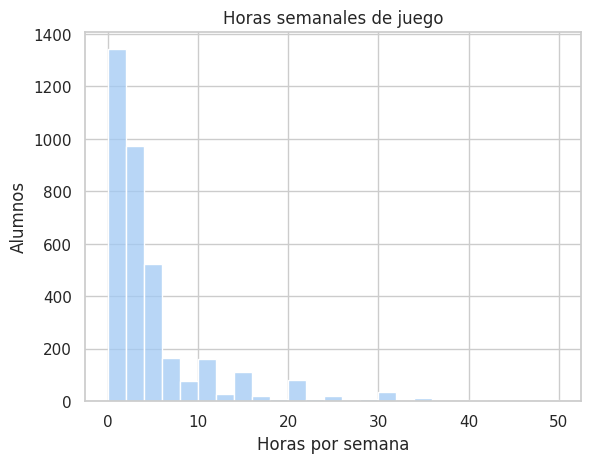

In [27]:
sns.histplot(datos["Horas_semana"], bins=25)
plt.title("Horas semanales de juego")
plt.xlabel("Horas por semana")
plt.ylabel("Alumnos")
plt.show()

📌 La distribución está muy sesgada a la derecha: la mayoría juega pocas horas, pero hay un grupo (~9%) que juega 14 h o más por semana.

### Horas de juego vs. puntaje GD-20

Quiero ver si los que juegan más horas también tienen un puntaje más alto de trastorno por videojuegos.

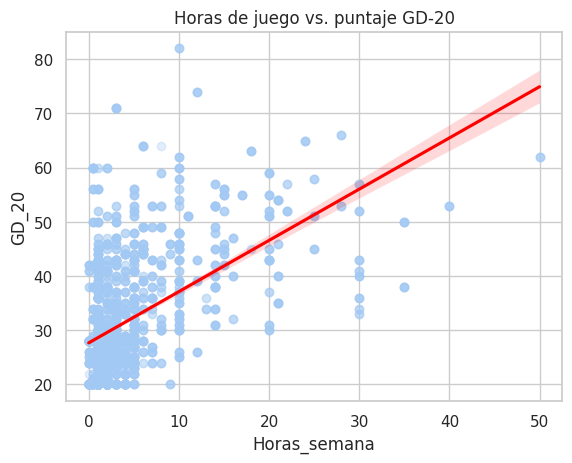

Correlación: 0.53


In [29]:
sns.regplot(data=datos, x="Horas_semana", y="GD_20",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Horas de juego vs. puntaje GD-20")
plt.show()

print("Correlación:", round(datos["Horas_semana"].corr(datos["GD_20"]), 2))

📌 Se ve una relación positiva moderada (**r ≈ 0.53**): a más horas de juego, mayor puntaje GD-20. Igual, hay bastante dispersión.

## 3\. Observaciones generales

El dataset está completo (sin nulos), pero todo viene codificado en números. Lo que más me llamó la atención es la relación entre las horas de juego y el puntaje GD-20, y que la mayoría de los alumnos son "Tipo_jugador" 1 (86%), lo que deja muy pocos casos en los grupos de riesgo. Las variables más interesantes son "Horas_semana", "GD_20" y los puntajes SEL.

# 📁 Dataset 4 – Estimaciones agrícolas \(Integrante: Franco Alfredo Díaz\)

## 📝 Descripción del Dataset

Estimaciones oficiales de la Secretaría de Agricultura de Argentina por cultivo, campaña, provincia y departamento, desde 1969 hasta 2024: superficie sembrada, superficie cosechada, producción (t) y rendimiento (kg/ha). Incluye 41 cultivos.

## Importación de Librerías

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

## 1\. Carga y exploración de datos

### Carga

Carga del CSV y estructura.

In [31]:
agro = pd.read_csv("estimaciones-agricolas-2026-03.csv")
print(agro.shape)
print(agro.dtypes)
agro.head(3)

(160499, 11)
cultivo                     object
anio                         int64
campania                    object
provincia                   object
provincia_id               float64
departamento                object
departamento_id            float64
superficie_sembrada_ha       int64
superficie_cosechada_ha      int64
produccion_tm                int64
rendimiento_kgxha            int64
dtype: object


,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
0,ajo,1969,1969/1970,Buenos Aires,6.0,25 de Mayo,6854.0,3,3,10,3333
1,ajo,1969,1969/1970,Buenos Aires,6.0,Adolfo Gonzales Chaves,6014.0,15,15,82,5467
2,ajo,1969,1969/1970,Buenos Aires,6.0,Almirante Brown,6028.0,2,2,8,4000


160.499 filas x 11 columnas. 4 variables de texto (cultivo, campaña, provincia, departamento) y 7 numéricas (incluye los códigos de provincia/departamento).

### Calidad de datos

Nulos, ceros y cultivos repetidos.

In [33]:
print("Nulos:\n", agro.isna().sum()[agro.isna().sum() > 0])
print("\n% filas con rendimiento = 0:", round((agro["rendimiento_kgxha"] == 0).mean() * 100, 1))
print("\nCultivos:", sorted(agro["cultivo"].unique()))

Nulos:
 provincia          8
provincia_id       8
departamento       8
departamento_id    8
dtype: int64

% filas con rendimiento = 0: 10.4

Cultivos: ['ajo', 'algodón', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'caña de azúcar', 'cebada cervecera', 'cebada forrajera', 'cebada total', 'cebolla total', 'centeno', 'colza', 'cártamo', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limón', 'lino', 'mandarina', 'maní', 'maíz', 'mijo', 'naranja', 'papa total', 'pomelo', 'poroto alubia', 'poroto negro', 'poroto otros', 'poroto total', 'soja 1ra', 'soja 2da', 'soja total', 'sorgo', 'trigo candeal', 'trigo total', 'tung', 'té', 'yerba mate']


- Solo 8 nulos, todos en provincia y departamento.
- ~10% de las filas tiene rendimiento 0 (cosechas perdidas o sin dato).
- Hay categorías "total" que suman subcategorías (p. ej. "soja total" = "soja 1ra" + "soja 2da"). Si se suma todo junto, se cuentan dos veces.

## 2\. Visualizaciones y análisis

### Evolución de la producción: soja, maíz y trigo

Producción nacional por año de los 3 cultivos principales.

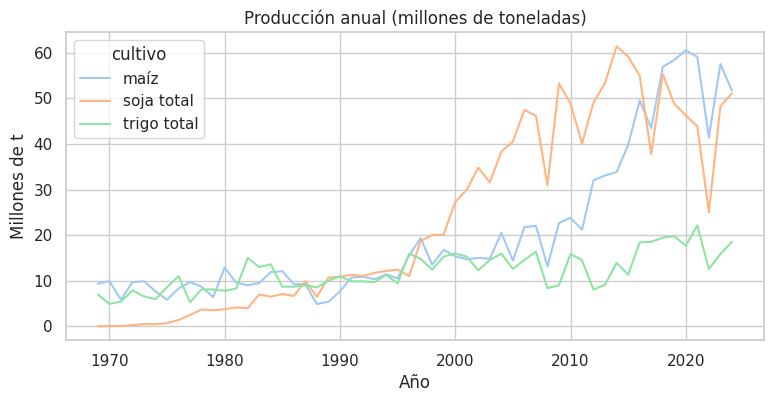

In [35]:
principales = agro[agro["cultivo"].isin(["soja total", "maíz", "trigo total"])]
prod = principales.pivot_table(index="anio", columns="cultivo", values="produccion_tm", aggfunc="sum") / 1e6

prod.plot(figsize=(9, 4), title="Producción anual (millones de toneladas)")
plt.xlabel("Año")
plt.ylabel("Millones de t")
plt.show()

📌
- La soja pasa de casi 0 en 1970 a ~60 Mt en 2015.
- El maíz supera a la soja desde ~2018.
- Caída fuerte en 2022, que coincide con la sequía.

### Provincias productoras de soja

Participación de cada provincia en la producción total de soja (todo el período).

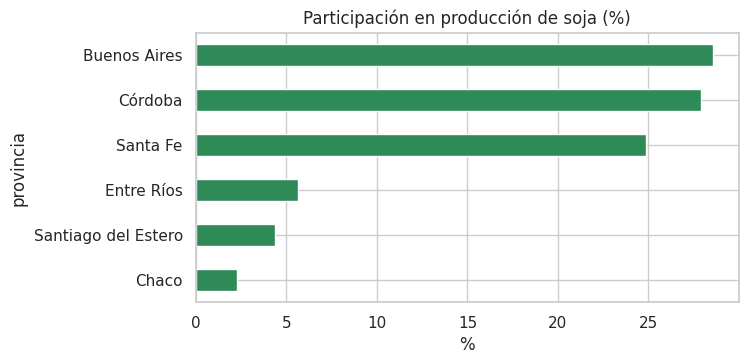

In [37]:
soja = agro[agro["cultivo"] == "soja total"]
part = (soja.groupby("provincia")["produccion_tm"].sum() / soja["produccion_tm"].sum() * 100).sort_values().tail(6)

part.plot(kind="barh", color="seagreen", figsize=(7, 3.5), title="Participación en producción de soja (%)")
plt.xlabel("%")
plt.show()

📌 Buenos Aires, Córdoba y Santa Fe concentran ~81% de la soja. Muy repartido entre las tres.

## 3\. Observaciones generales

- Dataset grande, largo en el tiempo y casi sin nulos.
- Cuidado con los cultivos "total" (doble conteo) y con los rendimientos en 0.
- Variables clave: "produccion_tm", "superficie_sembrada_ha", "rendimiento_kgxha". Sirve para series de tiempo o para predecir rendimiento.

# 📁 Dataset 5 – Exoplanetas 2021 \(Integrante: Federico Suárez\)

## 📝 Descripción del Dataset

Catálogo de exoplanetas confirmados hasta 2021 (basado en el NASA Exoplanet Archive). Cada fila es un planeta, con su método y año de descubrimiento, sus características orbitales (período, semieje mayor, excentricidad), su masa y los datos de su estrella (temperatura, radio, masa, metalicidad, distancia).

## Importación de Librerías

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

## 1\. Carga y exploración de datos

### Cargamos el catálogo

Primero cargamos el CSV y vemos qué columnas trae.

In [41]:
planetas = pd.read_csv("all_exoplanets_2021.csv")
print("Shape:", planetas.shape)
print(list(planetas.columns))
planetas.head()

Shape: (4575, 23)
['No.', 'Planet Name', 'Planet Host', 'Num Stars', 'Num Planets', 'Discovery Method', 'Discovery Year', 'Discovery Facility', 'Orbital Period Days', 'Orbit Semi-Major Axis', 'Mass', 'Eccentricity', 'Insolation Flux', 'Equilibrium Temperature', 'Spectral Type', 'Stellar Effective Temperature', 'Stellar Radius', 'Stellar Mass', 'Stellar Metallicity', 'Stellar Metallicity Ratio', 'Stellar Surface Gravity', 'Distance', 'Gaia Magnitude']


,No.,Planet Name,Planet Host,Num Stars,Num Planets,Discovery Method,Discovery Year,Discovery Facility,Orbital Period Days,Orbit Semi-Major Axis,...,Equilibrium Temperature,Spectral Type,Stellar Effective Temperature,Stellar Radius,Stellar Mass,Stellar Metallicity,Stellar Metallicity Ratio,Stellar Surface Gravity,Distance,Gaia Magnitude
0,1,11 Com b,11 Com,2,1,Radial Velocity,2007,Xinglong Station,326.03000,1.29,...,NaN,G8 III,4742.0,19.00,2.70,-0.35,[Fe/H],2.31,93.1846,4.44038
1,2,11 UMi b,11 UMi,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,516.21997,1.53,...,NaN,NaN,4213.0,29.79,2.78,-0.02,[Fe/H],1.93,125.3210,4.56216
2,3,14 And b,14 And,1,1,Radial Velocity,2008,Okayama Astrophysical Observatory,185.84000,0.83,...,NaN,K0 III,4813.0,11.00,2.20,-0.24,[Fe/H],2.63,75.4392,4.91781
3,4,14 Her b,14 Her,1,2,Radial Velocity,2002,W. M. Keck Observatory,1773.40002,2.93,...,NaN,NaN,5338.0,0.93,0.90,0.41,[Fe/H],4.45,17.9323,6.38300
4,5,16 Cyg B b,16 Cyg B,3,1,Radial Velocity,1996,Multiple Observatories,798.50000,1.66,...,NaN,NaN,5750.0,1.13,1.08,0.06,[Fe/H],4.36,21.1397,6.06428


Tenemos **4575 planetas y 23 columnas**. La columna "No." es solo un índice. Hay 6 columnas de texto (nombre, estrella, método, observatorio, etc.) y el resto son numéricas.

### ¿Cuántos datos faltan?

En catálogos astronómicos suele faltar mucha información, así que calculamos el % de nulos por columna.

In [43]:
nulos = (planetas.isna().mean() * 100).round(1).sort_values(ascending=False)
nulos[nulos > 0]

Insolation Flux                  91.9
Equilibrium Temperature          79.8
Spectral Type                    79.7
Eccentricity                     62.7
Mass                             56.2
Orbit Semi-Major Axis            39.6
Stellar Metallicity Ratio        30.2
Stellar Metallicity              30.0
Stellar Mass                     16.0
Stellar Surface Gravity          13.2
Stellar Radius                    9.8
Stellar Effective Temperature     7.6
Gaia Magnitude                    3.8
Orbital Period Days               3.5
Distance                          2.3
dtype: float64

Este es el punto débil del dataset: "Insolation Flux" tiene 92% de nulos y "Equilibrium Temperature" 80%. La masa del planeta falta en el 56% de los casos. En cambio, las variables del descubrimiento están completas.

## 2\. Visualizaciones y análisis

### Descubrimientos por año y método

Graficamos cuántos planetas se descubrieron cada año, separando los dos métodos principales del resto.

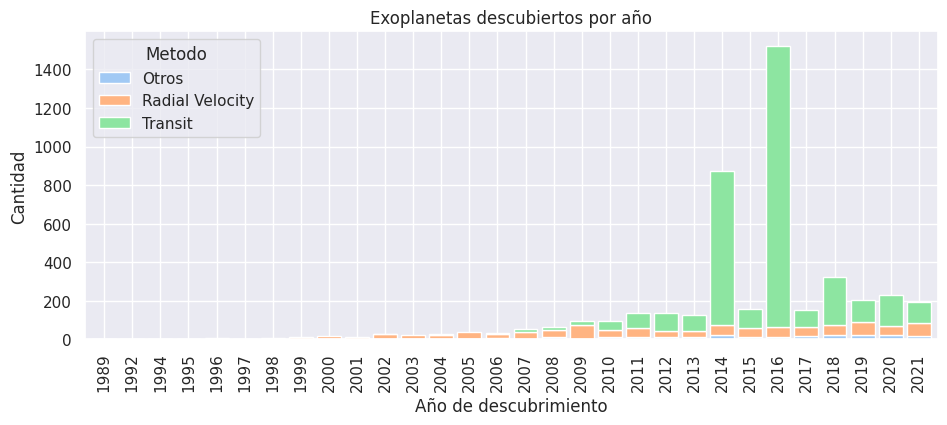

In [45]:
planetas["Metodo"] = planetas["Discovery Method"].where(
    planetas["Discovery Method"].isin(["Transit", "Radial Velocity"]), "Otros")

por_anio = planetas.groupby(["Discovery Year", "Metodo"]).size().unstack(fill_value=0)
por_anio.plot(kind="bar", stacked=True, figsize=(11, 4), width=0.85)
plt.title("Exoplanetas descubiertos por año")
plt.xlabel("Año de descubrimiento")
plt.ylabel("Cantidad")
plt.show()

📌 El método de **tránsito** domina (75% del total) y explica los picos de 2014 y 2016, que corresponden a las publicaciones masivas del telescopio **Kepler**. Antes de 2010, casi todo se descubría por velocidad radial.

### Período orbital vs. masa

Comparamos el período orbital con la masa (en masas terrestres) en escala logarítmica, coloreando según el método de descubrimiento.

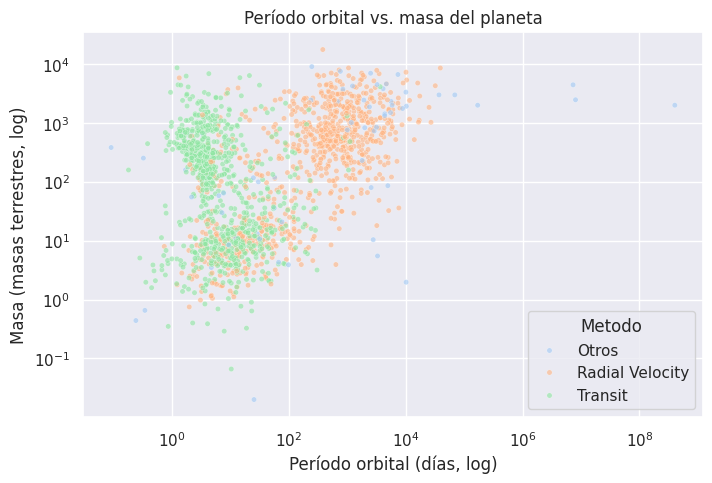

In [47]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=planetas, x="Orbital Period Days", y="Mass", hue="Metodo", hue_order=["Otros", "Radial Velocity", "Transit"], alpha=0.6, s=15)
plt.xscale("log")
plt.yscale("log")
plt.title("Período orbital vs. masa del planeta")
plt.xlabel("Período orbital (días, log)")
plt.ylabel("Masa (masas terrestres, log)")
plt.show()

📌 Cada método "ve" un tipo distinto de planeta: el tránsito encuentra sobre todo planetas de órbita corta (pocos días) y la velocidad radial detecta planetas más masivos, de tipo Júpiter. Se forman grupos bastante claros, algo interesante para hacer clustering.

## 3\. Observaciones generales

Es un dataset muy rico en variables físicas y con un tema atractivo. El gran problema es la cantidad de nulos en varias columnas, que obliga a elegir bien qué variables usar o a imputarlas. Lo más interesante: el sesgo que introduce el método de descubrimiento y la relación entre la masa, el período y las propiedades de la estrella.

# ✅ Conclusión del equipo

Después de analizar todos los datasets, el equipo ha decidido continuar el trabajo con el dataset:

## 🏆 Dataset elegido: Exoplanetas 2021 \(all\_exoplanets\_2021\)

## 📌 Motivos de la elección:

- Tiene muchas variables numéricas (orbitales y estelares) y 4575 registros.

- Trata una problemática científica actual y con datos reales (NASA Exoplanet Archive).

- Se ve potencial para aplicar IA: clasificar el método de descubrimiento, predecir la masa del planeta o agrupar tipos de planetas con clustering.

- Los nulos son un desafío, pero también una oportunidad para trabajar la limpieza y la imputación de datos.

## 💡 Próximos pasos

- Limpieza y preparación del dataset elegido\.

- Diseño de una solución basada en la problemática detectada\.

- Implementación y validación del modelo\.

# SEGUNDA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Análisis EDA \(según lo trabajaron en la entrega 1\)
Análisis univariado, bivariado y/o multivariado
4 hipótesis sobre el dataset
Gráficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.

## 🔍 Introducción

Vamos a \.\.\.

# 📁 Dataset seleccionado– \[Nombre del dataset\] 

## 📝 Descripción del Dataset

Describir de que se trata el dataset

## Importación de Librerías

In [26]:
#Importación de librerías

## 1\. Carga y exploración de datos

###  \[Nombre de la acción\]

Introducción a la acción

In [27]:
# Código para cargar el dataset y mostrar estructura

Interpretación de la acción

###  \[Nombre de la acción\]

Introducción a la acción

In [28]:
# Código para analizar el dataset y mostrar estructura

Interpretación de la acción

## 2\. Limpieza de Datos

## Analisis Univariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [29]:
#Gráfico 1

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## 3\. Visualizaciones y análisis

## Analisis Univariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [30]:
#Gráfico 1

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## Analisis Bivariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [31]:
#Gráfico 1

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 2

In [32]:
#Gráfico 2

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 3

In [33]:
#Gráfico 3

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## Analisis Multivariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [34]:
#Gráfico 1

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 2

In [35]:
#Gráfico 2

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 3

In [36]:
#Gráfico 3

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## 4\. Planteo de Hipótesis

###  \[Hipótesis 1\]

Introducción Hipótesis  

In [37]:
#desarrollo Hipótesis 

In [38]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 2\]

Introducción Hipótesis  

In [39]:
#desarrollo Hipótesis 

In [40]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 3\]

Introducción Hipótesis  

In [41]:
#desarrollo Hipótesis 

In [42]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 4\]

Introducción Hipótesis  

In [43]:
#desarrollo Hipótesis 

In [44]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

### \[Hipótesis 2\]

# ✅ Conclusión del equipo

Hemos podido observar que\.\.\.

# TERCERA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Introducción y descripción del dataset
Planteamiento del objetivo del proyecto
Planteamiento de hipótesis y resumen de las conclusiones sobre las hipótesis
Análisis EDA
Análisis univariado
Análisis Bivariado y/o multivariado
Graficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.
Aplicación de modelos de Regresión,
Clasificación o Agrupación según lo planteado en el objetivo\.
\(mínimo 3 modelos\)
Métricas de evaluación del modelo aplicado
Selección del modelo más indicado en base a las métricas\.

## 🔍 Introducción 

# 📁 Dataset elegido – \[Nombre del dataset\] 

## 📝 Descripción del Dataset

Describir de que se trata el dataset

## Importación de Librerías

In [45]:
#Importación de librerías

## 1\. Carga y exploración de datos

###  \[Nombre de la acción\]

Introducción a la acción

In [46]:
# Código para cargar el dataset y mostrar estructura

Interpretación de la acción

###  \[Nombre de la acción\]

Introducción a la acción

In [47]:
# Código para analizar el dataset y mostrar estructura

Interpretación de la acción

## 2\. Visualizaciones y análisis

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [48]:
#Gráfico 1

📌 Interpretación del gráfico

Introducción al Gráfico 2

In [49]:
#Gráfico 2

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

# ✅ Conclusión del equipo

Después de analizar todos los datasets, el equipo ha decidido continuar el trabajo con el dataset:

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=550f70db-7aa4-46ac-95e6-5dc38c53fb55' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>